In [3]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
enso_nao_flags = pd.read_csv('/sto0/user/Kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
enso_nao_flags = enso_nao_flags.set_index(['model', 'realization'])

In [5]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
models = ['CanESM5', 'GISS-E2-1-G','MPI-ESM1-2-LR', 'MIROC-ES2L', 'UKESM1-0-LL']
colors = ['darkmagenta', 'darkorange', 'royalblue', 'limegreen', 'deepskyblue']
plotdir = '/sto0/user/Kperny/VolMIP_stratosphere/plots/'


In [8]:
ds_ta = {} 
ds_ua = {} 
df = []
for model in models:
    ds_ta[model] = xr.open_dataset(path + model + '/ta_anomaly_' + model + '.nc')
    ds_ua[model] = xr.open_dataset(path + model + '/ua_anomaly_' + model + '.nc')
    tmp = ds_ta[model].sel(time=slice('1991-12', '1992-02')).mean('time').ano.to_dataframe()
    tmp = tmp.reset_index().drop('lon', axis=1)
    tmp['model'] = model
    df.append(tmp)

/tmp/ipykernel_4089330/167430861.py:5: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds_ta[model] = xr.open_dataset(path + model + '/ta_anomaly_' + model + '.nc')
/tmp/ipykernel_4089330/167430861.py:6: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds_ua[model] = xr.open_dataset(path + model + '/ua_anomaly_' + model + '.nc')


In [7]:
df_models = pd.concat(df)
df_models = df_models.set_index(['model','ens'])

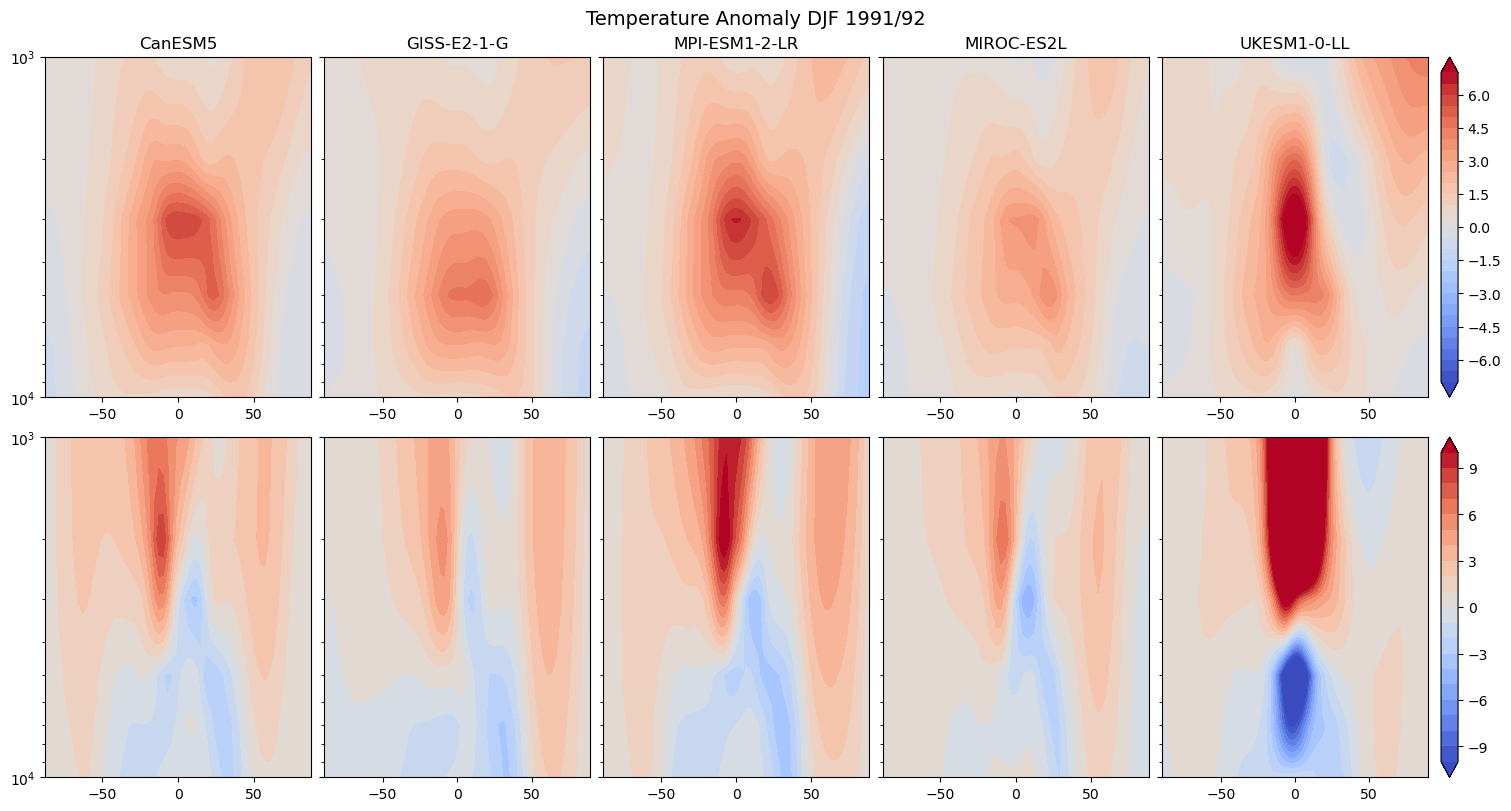

In [12]:
fig, axs = plt.subplots(2,5, figsize=(15,8), layout='constrained', sharey=True)

for i, model in enumerate(models):
    tmp = ds_ta[model].ano.sel(time=slice('1991-12','1992-02')).mean(['time', 'ens'])
    tmp_ua = ds_ua[model].ano.sel(time=slice('1991-12','1992-02')).mean(['time', 'ens'])

    p = axs[0,i].contourf(tmp.lat, tmp.plev, tmp.squeeze(), cmap='coolwarm', levels=np.linspace(-7,7,29), extend='both')
    d = axs[1,i].contourf(tmp_ua.lat, tmp_ua.plev, tmp_ua.squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')

    axs[0,i].set_ylim(10000, 1000)
    axs[0,i].set_yscale('log')
    axs[0,i].set_title(model)

cbar = fig.colorbar(p, ax=axs[0:1,4], orientation='vertical')
cbar = fig.colorbar(d, ax=axs[1:2,4], orientation='vertical')
plt.suptitle('Temperature Anomaly DJF 1991/92', fontsize=14)
plt.savefig(plotdir + 'zonal_DJF_ta_ua.png', dpi=200)

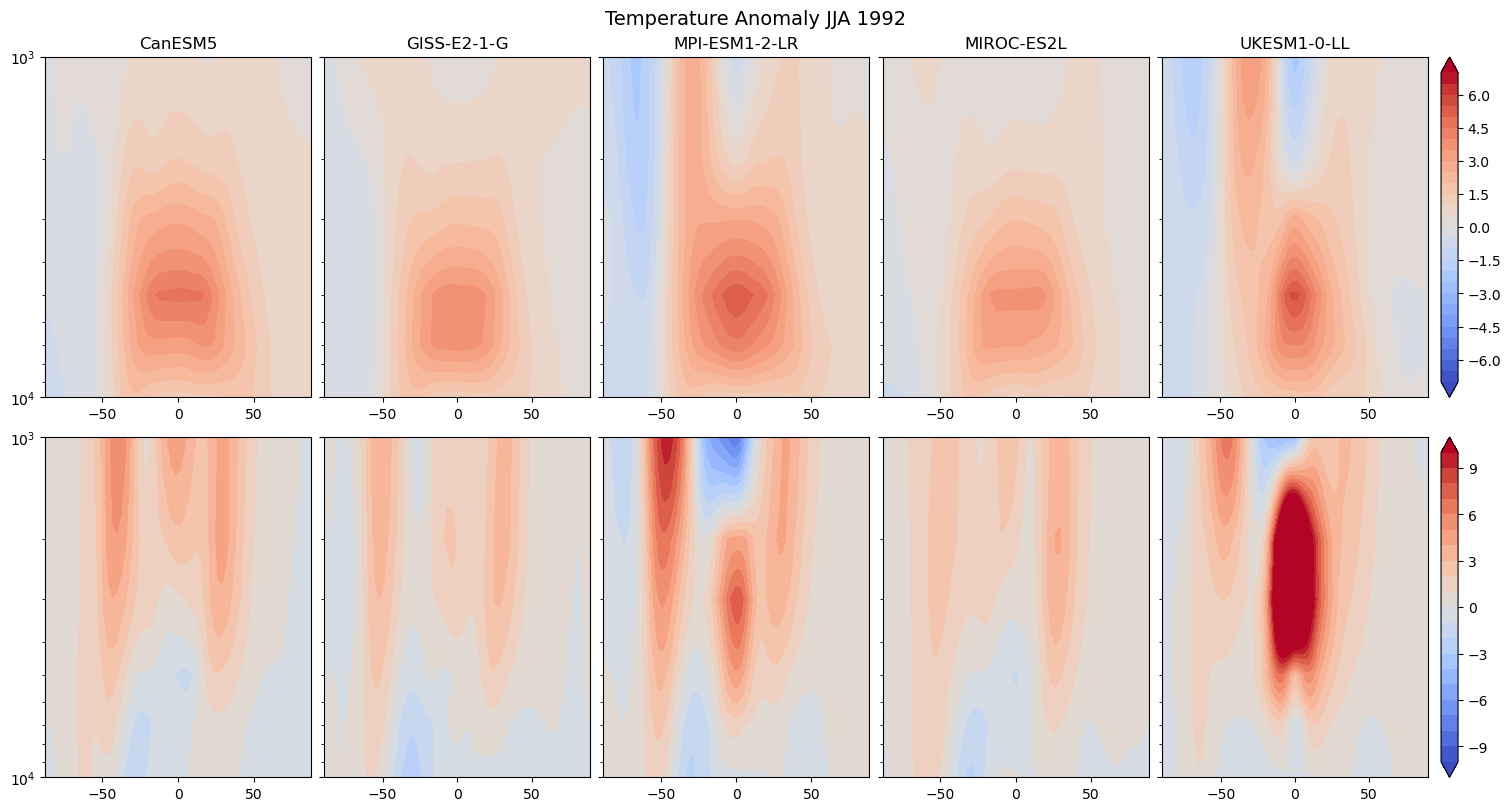

In [23]:
fig, axs = plt.subplots(2,5, figsize=(15,8), layout='constrained', sharey=True)

for i, model in enumerate(models):
    tmp = ds_ta[model].ano.sel(time=slice('1992-06','1992-08')).mean(['time', 'ens'])
    tmp_ua = ds_ua[model].ano.sel(time=slice('1992-06','1992-08')).mean(['time', 'ens'])

    p = axs[0,i].contourf(tmp.lat, tmp.plev, tmp.squeeze(), cmap='coolwarm', levels=np.linspace(-7,7,29), extend='both')
    d = axs[1,i].contourf(tmp_ua.lat, tmp_ua.plev, tmp_ua.squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')

    axs[0,i].set_ylim(10000, 1000)
    axs[0,i].set_yscale('log')
    axs[0,i].set_title(model)

cbar = fig.colorbar(p, ax=axs[0:1,4], orientation='vertical')
cbar = fig.colorbar(d, ax=axs[1:2,4], orientation='vertical')
plt.suptitle('Temperature Anomaly JJA 1992', fontsize=14)
plt.savefig(plotdir + 'zonal_JJA_ta_ua.png', dpi=200)

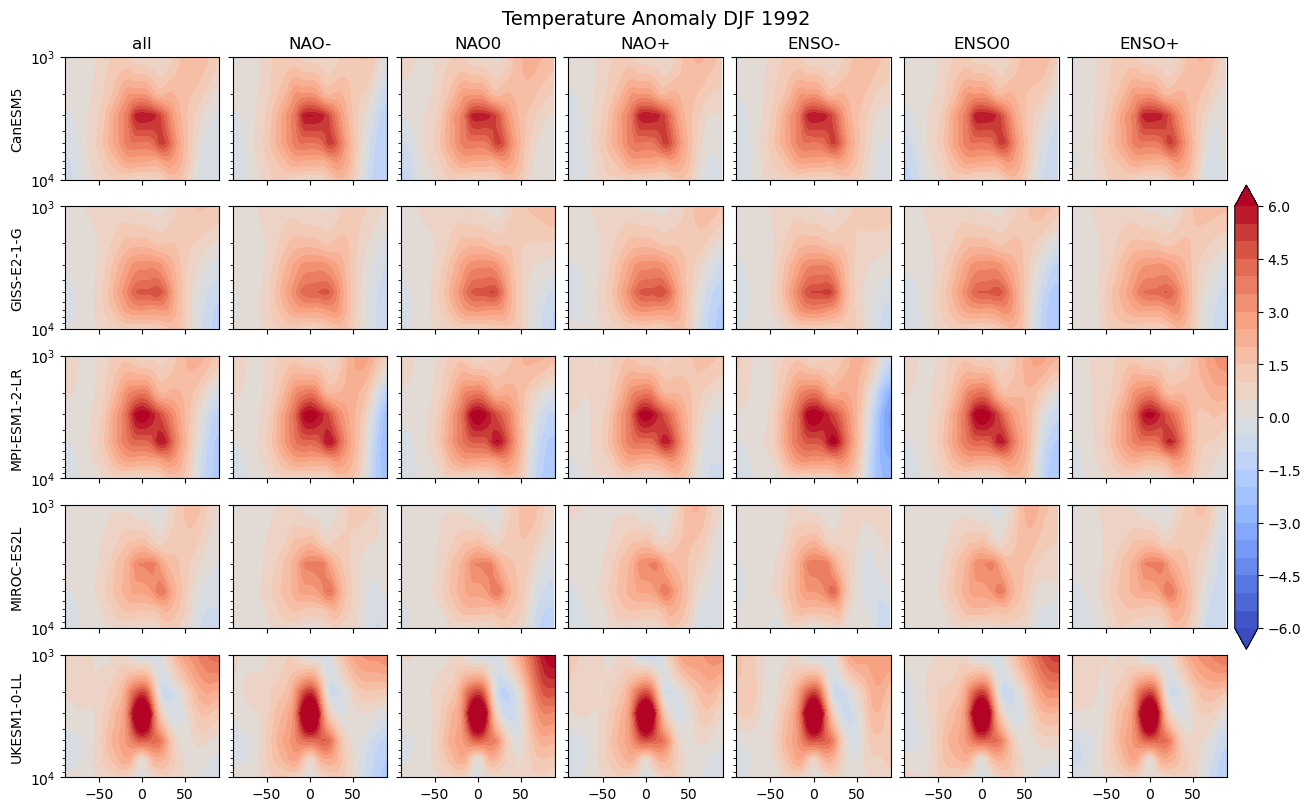

In [80]:
# NAO and ENSO flags
fig, axs = plt.subplots(5,7, figsize=(13,8), layout='constrained', sharey=True, sharex=True)

indexes = [-1,0,1,-1,0,1]
flags = ['nao_flag','nao_flag','nao_flag','enso_flag','enso_flag','enso_flag']
names = ['NAO-', 'NAO0', 'NAO+', 'ENSO-', 'ENSO0', 'ENSO+']

for i, model in enumerate(models):
    tmp = ds_ta[model].ano.sel(time=slice('1991-12','1992-02'))
    # nao_neutral = enso_nao_flags.where(enso_nao_flags.nao_flag==0).loc[model].dropna().index
    # nao_positiv = enso_nao_flags.where(enso_nao_flags.nao_flag==1).loc[model].dropna().index
    # nao_negative = enso_nao_flags.where(enso_nao_flags.nao_flag==-1).loc[model].dropna().index

    # enso_neutral = enso_nao_flags.where(enso_nao_flags.enso_flag==0).loc[model].dropna().index
    # enso_positiv = enso_nao_flags.where(enso_nao_flags.enso_flag==1).loc[model].dropna().index
    # enso_negative = enso_nao_flags.where(enso_nao_flags.enso_flag==-1).loc[model].dropna().index

    all = tmp.mean(['time', 'ens'])
    p = axs[i,0].contourf(all.lat, all.plev, all.squeeze(), cmap='coolwarm', levels=np.linspace(-6,6,25), extend='both')

    for j in range(6):
         flag = enso_nao_flags.where(enso_nao_flags[flags[j]]==indexes[j]).loc[model].dropna().index
         axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=flag).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-6,6,25), extend='both')
         axs[0,j+1].set_title(names[j])
    axs[i,0].set_ylim(10000, 1000)
    axs[i,0].set_yscale('log')
    axs[i,0].set_ylabel(model)
    axs[0,0].set_title('all')

cbar = fig.colorbar(p, ax=axs[0:5,6], orientation='vertical')
plt.suptitle('Temperature Anomaly DJF 1992', fontsize=14)
plt.savefig(plotdir + 'zonal_DJF_ta_enso_nao.png', dpi=200)

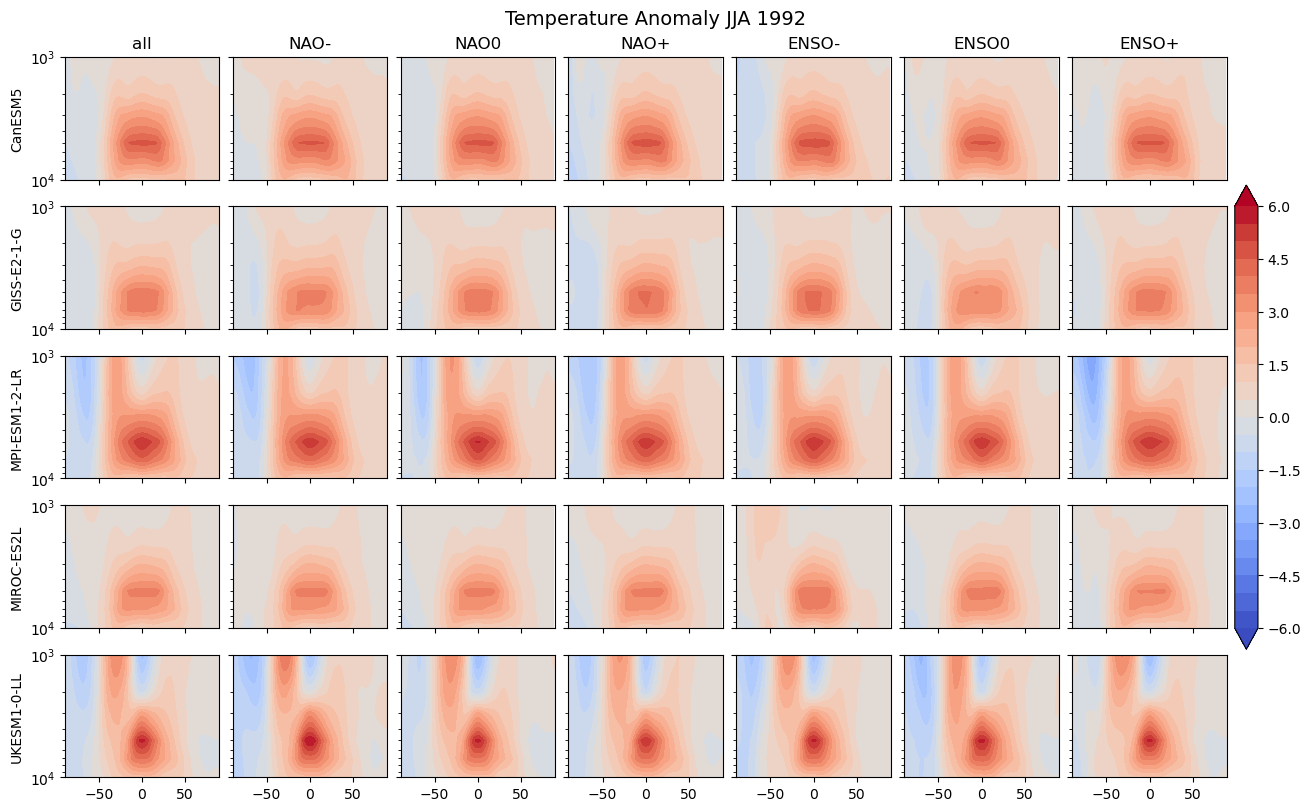

In [79]:
# NAO and ENSO flags
fig, axs = plt.subplots(5,7, figsize=(13,8), layout='constrained', sharey=True, sharex=True)

indexes = [-1,0,1,-1,0,1]
flags = ['nao_flag','nao_flag','nao_flag','enso_flag','enso_flag','enso_flag']
names = ['NAO-', 'NAO0', 'NAO+', 'ENSO-', 'ENSO0', 'ENSO+']

for i, model in enumerate(models):
    tmp = ds_ta[model].ano.sel(time=slice('1992-06','1992-08'))
    all = tmp.mean(['time', 'ens'])
    p = axs[i,0].contourf(all.lat, all.plev, all.squeeze(), cmap='coolwarm', levels=np.linspace(-6,6,25), extend='both')

    for j in range(6):
         flag = enso_nao_flags.where(enso_nao_flags[flags[j]]==indexes[j]).loc[model].dropna().index
         axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=flag).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-6,6,25), extend='both')
         axs[0,j+1].set_title(names[j])
    axs[i,0].set_ylim(10000, 1000)
    axs[i,0].set_yscale('log')
    axs[i,0].set_ylabel(model)
    axs[0,0].set_title('all')

cbar = fig.colorbar(p, ax=axs[0:5,6], orientation='vertical')
plt.suptitle('Temperature Anomaly JJA 1992', fontsize=14)
plt.savefig(plotdir + 'zonal_JJA_ta_enso_nao.png', dpi=200)

set()
set()


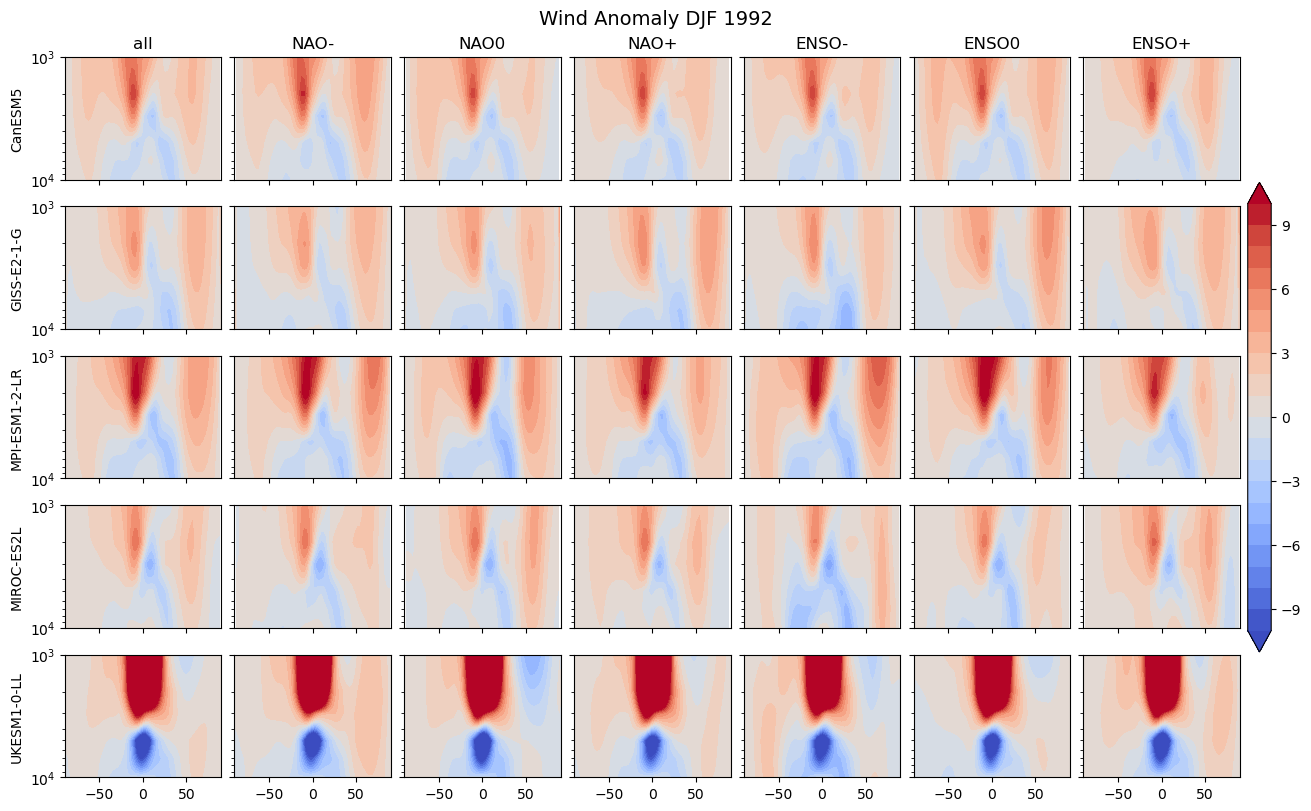

In [ ]:
# NAO and ENSO flags
fig, axs = plt.subplots(5,7, figsize=(13,8), layout='constrained', sharey=True, sharex=True)

indexes = [-1,0,1,-1,0,1]
flags = ['nao_flag','nao_flag','nao_flag','enso_flag','enso_flag','enso_flag']
names = ['NAO-', 'NAO0', 'NAO+', 'ENSO-', 'ENSO0', 'ENSO+']

for i, model in enumerate(models):
    tmp = ds_ua[model].ano.sel(time=slice('1991-12','1992-02'))

    all = tmp.mean(['time', 'ens'])
    p = axs[i,0].contourf(all.lat, all.plev, all.squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')

    for j in range(6):
        flag = enso_nao_flags.where(enso_nao_flags[flags[j]]==indexes[j]).loc[model].dropna().index
        try:
            axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=flag).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')
        except KeyError:
            axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=tmp.ens[tmp.ens.isin(flag)]).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')
            print(set(tmp.ens[tmp.ens.isin(flag)].values) - set(flag))
        axs[0,j+1].set_title(names[j])
    axs[i,0].set_ylim(10000, 1000)
    axs[i,0].set_yscale('log')
    axs[i,0].set_ylabel(model)
    axs[0,0].set_title('all')

cbar = fig.colorbar(p, ax=axs[0:5,6], orientation='vertical')
plt.suptitle('Wind Anomaly DJF 1992', fontsize=14)
plt.savefig(plotdir + 'zonal_DJF_ua_enso_nao.png', dpi=200)

set()
set()


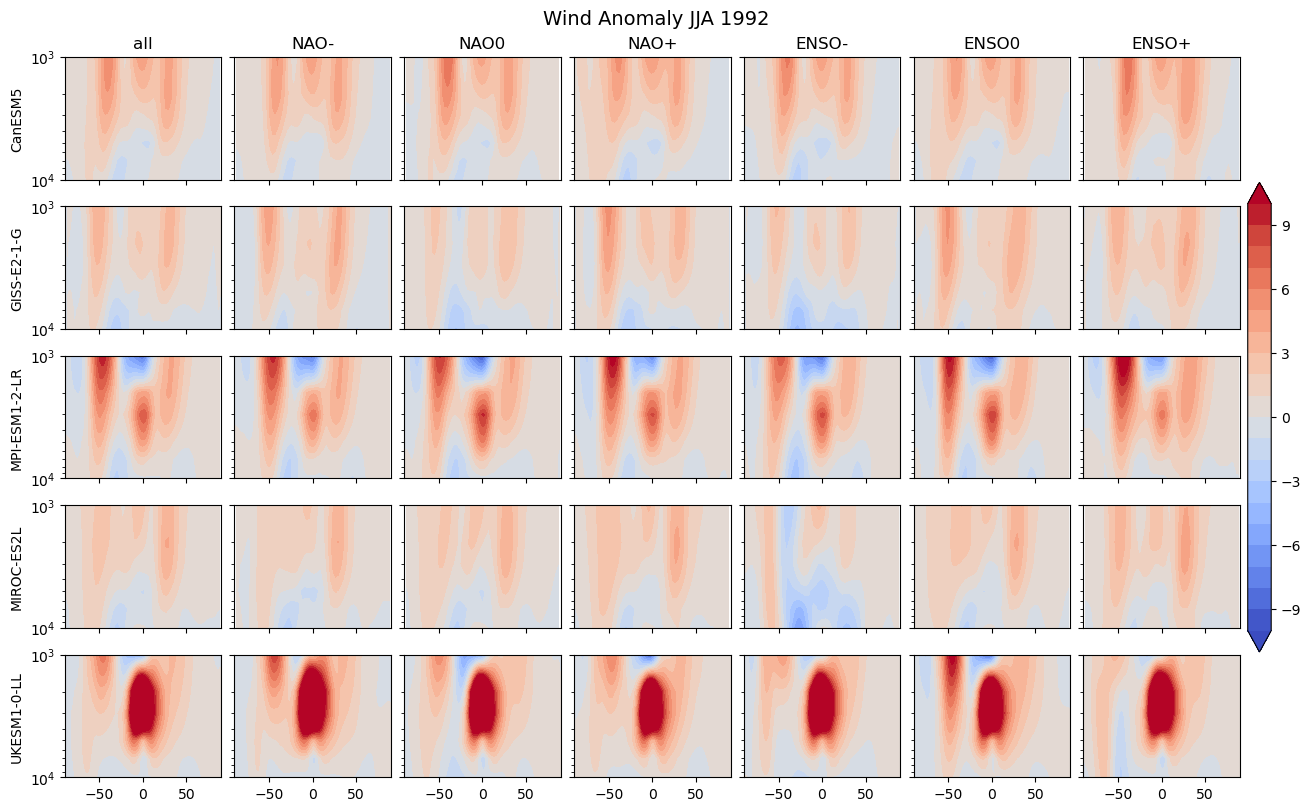

In [81]:
# NAO and ENSO flags
fig, axs = plt.subplots(5,7, figsize=(13,8), layout='constrained', sharey=True, sharex=True)

indexes = [-1,0,1,-1,0,1]
flags = ['nao_flag','nao_flag','nao_flag','enso_flag','enso_flag','enso_flag']
names = ['NAO-', 'NAO0', 'NAO+', 'ENSO-', 'ENSO0', 'ENSO+']

for i, model in enumerate(models):
    tmp = ds_ua[model].ano.sel(time=slice('1992-06','1992-08'))

    all = tmp.mean(['time', 'ens'])
    p = axs[i,0].contourf(all.lat, all.plev, all.squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')

    for j in range(6):
        flag = enso_nao_flags.where(enso_nao_flags[flags[j]]==indexes[j]).loc[model].dropna().index
        try:
            axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=flag).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')
        except KeyError:
            axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=tmp.ens[tmp.ens.isin(flag)]).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')
            print(set(tmp.ens[tmp.ens.isin(flag)].values) - set(flag))
        axs[0,j+1].set_title(names[j])
    axs[i,0].set_ylim(10000, 1000)
    axs[i,0].set_yscale('log')
    axs[i,0].set_ylabel(model)
    axs[0,0].set_title('all')

cbar = fig.colorbar(p, ax=axs[0:5,6], orientation='vertical')
plt.suptitle('Wind Anomaly JJA 1992', fontsize=14)
plt.savefig(plotdir + 'zonal_JJA_ua_enso_nao.png', dpi=200)